# Quantitative Foundations for Biology
## Taylor Approximation: Making Nonlinear Functions Simple


## 1. Why approximate a function?
Biological models frequently contain exponential, logarithmic, and rational functions. A polynomial is often easier to evaluate, differentiate, and interpret. **But it is only a local substitute**.

For a smooth function near $x=a$, the simplest approximation is the tangent line:
$$f(x)\approx f(a)+f'(a)(x-a).$$
The slope tells us the response to a small change in the input. For $f(x)=e^x$ at $a=0$, this becomes $e^x\approx1+x$.

**Think–pair–share:** Why should the tangent approximation be good near $x=0$ but less reliable at $x=2$?

## 2. Constructing a Taylor polynomial
We seek $T_n(x)=c_0+c_1(x-a)+\cdots+c_n(x-a)^n$ whose value and first $n$ derivatives agree with $f$ at $a$.

Matching at $a$ gives
$$c_0=f(a),\quad c_1=f'(a),\quad 2!c_2=f''(a),\quad\ldots,\quad n!c_n=f^{(n)}(a).$$
Therefore,
$$\boxed{T_n(x)=\sum_{k=0}^n\frac{f^{(k)}(a)}{k!}(x-a)^k.}$$

An expansion at $a=0$ is called a **Maclaurin polynomial**. For $f(x)=e^x$, all derivatives at zero equal one:
$$T_n(x)=1+x+\frac{x^2}{2!}+\cdots+\frac{x^n}{n!}.$$

**Important:** The expansion point $a$, the polynomial degree $n$, and the distance $|x-a|$ all influence accuracy.

## 3. Interactive demonstration: change the Taylor degree and expansion point

The Taylor polynomial is constructed **around the center $a$**. Every polynomial, including degree zero, must pass through $(a,e^a)$.

- Move **Degree** from 0 to 5 to see how additional terms change the approximation.
- Move **Center $a$** to see how the approximation changes when it is constructed at a different location.
- At degree zero, $T_0(x;a)=e^a$ is a horizontal line that must pass through the black dot at $(a,e^a)$.

The right panel shows the absolute error across the plotted interval. The error at the expansion point must always be zero (up to roundoff).

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from math import factorial

def exp_taylor(x, order, a=0.0):
    """Taylor polynomial of exp(x) about the center a."""
    x = np.asarray(x, dtype=float)
    delta = x - a
    return np.exp(a) * sum(delta**k / factorial(k) for k in range(order + 1))


def plot_exp_taylor(order=2, a=0.0):
    """Display the exact exponential and its degree-order Taylor polynomial."""
    x = np.linspace(-2, 2.5, 500)
    exact = np.exp(x)
    approximate = exp_taylor(x, order, a)
    error = np.abs(exact - approximate)

    fig, (ax, err_ax) = plt.subplots(1, 2, figsize=(11, 3.8))
    ax.plot(x, exact, linewidth=2.5, label='Exact $e^x$')
    ax.plot(x, approximate, '--', linewidth=2,
            label=f'Taylor degree {order} (center {a:g})')
    ax.axvline(a, linestyle=':', color='gray', alpha=0.8)
    ax.scatter([a], [np.exp(a)], s=85, color='black', zorder=6,
               label='Common point $(a,e^a)$')
    ax.set(xlabel='$x$', ylabel='$f(x)$', title='Function and Taylor polynomial',
           xlim=(-2, 2.5), ylim=(-1, 13))
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

    err_ax.plot(x, error)
    err_ax.axvline(a, linestyle=':', color='gray', alpha=0.8)
    err_ax.scatter([a], [0], s=60, color='black', zorder=6)
    err_ax.set(xlabel='$x$', ylabel='Absolute error',
               title='Error: $|e^x-T_n(x;a)|$', xlim=(-2, 2.5))
    err_ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    at_center = float(exp_taylor(a, order, a))
    print(f'Center a = {a:g}; degree n = {order}')
    print(f'Exact f(a) = {np.exp(a):.7f}; Taylor T_n(a) = {at_center:.7f}')
    if order == 0:
        print(f'Zeroth order: T_0(x;a) = exp(a) = {np.exp(a):.7f} for every x.')


# Only two controls: polynomial degree and center of expansion.
widgets.interact(
    plot_exp_taylor,
    order=widgets.IntSlider(value=2, min=0, max=10, description='Degree'),
    a=widgets.FloatSlider(value=0, min=-1, max=1, step=0.25, description='Center a')
);


interactive(children=(IntSlider(value=2, description='Degree', max=10), FloatSlider(value=0.0, description='Ce…

**Classroom prompts**
1. Choose degree $n=0$ and center $a=1$. What is the height of the horizontal line? Why?
2. Choose center $a=0$ and increase the degree. Where is the approximation most accurate?
3. Keeping the same degree, move the center to $a=1$. How does the region of best agreement shift?
4. What does the error curve show at $x=a$ for every degree?

**Later, for numerical error calculations**, we evaluate $T_n(x;a)$ at a specified $x$ using Python (Section 5). No separate evaluation-point slider is needed here.

## 4. Worked mathematical examples
### Example A: Square root
Expand $f(x)=\sqrt{1+x}$ about zero. Since $f(0)=1$, $f'(0)=1/2$, and $f''(0)=-1/4$,
$$\sqrt{1+x}\approx 1+\frac{x}{2}-\frac{x^2}{8}.$$
At $x=0.1$, $T_2(0.1)=1.04875$; the exact value is $\sqrt{1.1}\approx1.04880885$.

### Example B: Sine
$$\sin x\approx x-\frac{x^3}{3!}+\frac{x^5}{5!}.$$
Angles must be in **radians**. At $x=0.3$, the linear approximation gives $0.3$, while the cubic gives $0.2955$ (exact $\approx0.295520$).

### Example C: Logarithm
$$\ln(1+x)\approx x-\frac{x^2}{2}+\frac{x^3}{3},\qquad |x|<1.$$
Unlike the exponential series, this series about zero has a **limited radius of convergence**. More terms do not rescue the series at every $x$.

In [ ]:
x = np.linspace(-0.85, 0.85, 350)
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(x, np.log1p(x), label='Exact $\ln(1+x)$', lw=2.5)
for degree in (1,2,3,6):
    approx = sum((-1)**(k+1)*x**k/k for k in range(1,degree+1))
    ax.plot(x,approx,label=f'Degree {degree}')
ax.set(xlabel='$x$',ylabel='$f(x)$',title='Logarithm: convergence is local')
ax.legend();ax.grid(alpha=.25);plt.show()

## 5. How accurate is the approximation?
Define the **absolute error** $E_{abs}=|f(x)-T_n(x)|$ and, when $f(x)\ne0$, the **relative error** $E_{rel}=E_{abs}/|f(x)|$.

Taylor's theorem says that, if the required derivatives exist,
$$f(x)=T_n(x)+R_n(x),\qquad R_n(x)=\frac{f^{(n+1)}(\xi)}{(n+1)!}(x-a)^{n+1}$$
for some $\xi$ between $a$ and $x$. For the exponential centered at zero,
$$|R_n(x)|\le\frac{e^{|x|}|x|^{n+1}}{(n+1)!}.$$
This bound may be conservative; it is not generally the actual error.

**Numerical task:** Fill in the table and compare the actual error with the bound.

In [ ]:
x0 = 1.0
print(f"{'Degree':>6} {'Taylor':>12} {'Actual error':>15} {'Error bound':>15}")
for degree in range(0, 8):
    estimate = float(exp_taylor(x0, degree))
    actual = abs(np.exp(x0) - estimate)
    bound = np.exp(abs(x0))*abs(x0)**(degree+1)/factorial(degree+1)
    print(f'{degree:6d} {estimate:12.7f} {actual:15.7g} {bound:15.7g}')

## 6. Biological application: Michaelis–Menten kinetics
An enzyme's reaction rate often follows
$$v(S)=\frac{V_{\max}S}{K_m+S}.$$
Here $S$ and $K_m$ have concentration units; $V_{\max}$ has reaction-rate units.

**First find a dimensionless parameter:** $u=S/K_m$. Then
$$\frac{v}{V_{\max}}=\frac{u}{1+u}=u-u^2+u^3-u^4+\cdots,\qquad |u|<1.$$
Consequently, at low substrate concentration ($S\ll K_m$),
$$\boxed{v(S)\approx\frac{V_{\max}}{K_m}S.}$$

**Interpretation:** An intrinsically saturating process looks linear at sufficiently low substrate concentration. The quadratic term quantifies the first correction to that linear behavior. The expansion about zero is not a useful series for $S\ge K_m$.

**Worked numerical example:** Let $V_{\max}=100\;\mu\mathrm{mol/min}$, $K_m=2\;\mathrm{mM}$, and $S=0.2\;\mathrm{mM}$, so $u=0.1$.

- Exact: $v=100(0.1/1.1)=9.0909\;\mu\mathrm{mol/min}$.
- Linear: $v_1=100(0.1)=10$.
- Quadratic: $v_2=100(0.1-0.01)=9$.
- Cubic: $v_3=100(0.1-0.01+0.001)=9.1$.

Relative errors: 10%, 1%, and 0.1%, respectively.

In [12]:
def mm_taylor(S, vmax, km, order):
    u = np.asarray(S, dtype=float)/km
    return vmax * sum((-1)**(k-1)*u**k for k in range(1,order+1))

def plot_mm(order=2, substrate_ratio=0.1):
    vmax, km = 100.0, 2.0
    u = np.linspace(0, 1.2, 450)
    S = km*u
    exact = vmax*S/(km+S)
    approx = mm_taylor(S,vmax,km,order)
    fig,(ax,axerr)=plt.subplots(1,2,figsize=(11,3.8))
    ax.plot(u,exact,label='Exact rate',lw=2.5)
    ax.plot(u,approx,'--',label=f'Taylor degree {order}',lw=2)
    ax.axvline(substrate_ratio,ls=':',color='gray')
    ax.set(xlabel=r'$S/K_m$',ylabel=r'Rate ($\mu$mol/min)',title='Enzyme kinetics')
    ax.legend();ax.grid(alpha=.25)
    axerr.plot(u,abs(exact-approx))
    axerr.axvline(substrate_ratio,ls=':',color='gray')
    axerr.set(xlabel=r'$S/K_m$',ylabel='Absolute error',title='Taylor error')
    axerr.grid(alpha=.25);plt.tight_layout();plt.show()
    S0=km*substrate_ratio
    truth=vmax*S0/(km+S0)
    pred=float(mm_taylor(S0,vmax,km,order))
    print(f'S = {S0:.3f} mM | exact = {truth:.5f} | Taylor = {pred:.5f} µmol/min')
    if truth: print(f'Relative error = {100*abs(pred-truth)/truth:.3f}%')

widgets.interact(plot_mm,
    order=widgets.IntSlider(value=2,min=1,max=8,description='Degree'),
    substrate_ratio=widgets.FloatSlider(value=.1,min=0,max=1.2,step=.05,description='S/Km'));


interactive(children=(IntSlider(value=2, description='Degree', max=8, min=1), FloatSlider(value=0.1, descripti…

### A different expansion point: near a physiological operating condition
Low-substrate expansions are not the only choice. If an experiment operates near $S_0$, we can linearize **there**:
$$v(S)\approx v(S_0)+v'(S_0)(S-S_0),\qquad v'(S_0)=\frac{V_{\max}K_m}{(K_m+S_0)^2}.$$
This gives the local sensitivity of reaction rate to a small change in substrate concentration. It works near $S_0$ even when $S_0/K_m$ is not small.

**Discussion:** What is the advantage of expanding near the measured operating point rather than always at $S=0$?

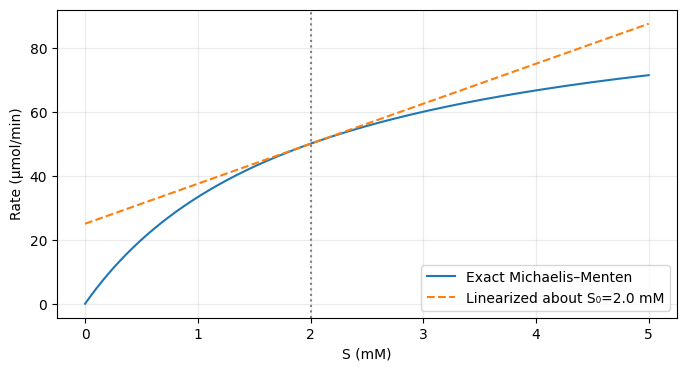

At S0=2.0 mM, rate=50.00 µmol/min and sensitivity=12.50 (µmol/min)/mM


In [13]:
vmax, km, s0 = 100., 2., 2.
s = np.linspace(0,5,400)
exact = vmax*s/(km+s)
v0 = vmax*s0/(km+s0)
slope = vmax*km/(km+s0)**2
local_linear = v0 + slope*(s-s0)
plt.figure(figsize=(8,4))
plt.plot(s,exact,label='Exact Michaelis–Menten')
plt.plot(s,local_linear,'--',label=f'Linearized about S₀={s0} mM')
plt.axvline(s0,ls=':',color='gray')
plt.xlabel('S (mM)');plt.ylabel('Rate (µmol/min)');plt.legend();plt.grid(alpha=.25);plt.show()
print(f'At S0={s0} mM, rate={v0:.2f} µmol/min and sensitivity={slope:.2f} (µmol/min)/mM')

## 7. Second biological example: bacterial growth
For exponential growth $N(t)=N_0e^{rt}$, the Taylor expansion at $t=0$ is
$$N(t)\approx N_0\left[1+rt+\frac{(rt)^2}{2}\right].$$
The **dimensionless** small parameter is $rt$. A small number of minutes does not guarantee a good approximation if the growth rate is very large.

**Worked example:** With $r=0.5\;\mathrm{h}^{-1}$ and $t=0.2\;\mathrm{h}$, $rt=0.1$. The linear approximation gives $1.1N_0$, the quadratic gives $1.105N_0$, and the exact value is $1.105170...N_0$.

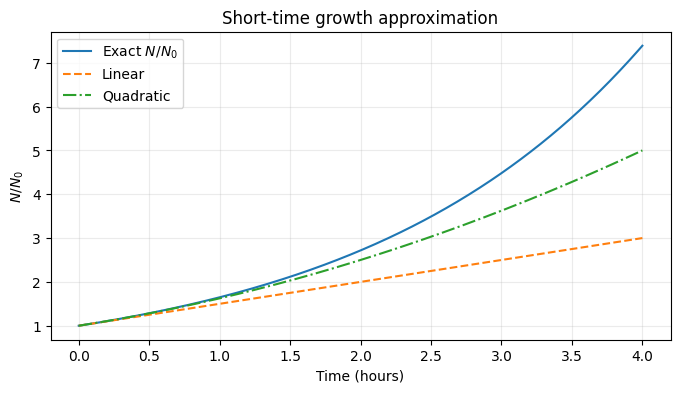

In [14]:
r=0.5  # 1/hour
t=np.linspace(0,4,400)
z=r*t
plt.figure(figsize=(8,4))
plt.plot(t,np.exp(z),label='Exact $N/N_0$')
plt.plot(t,1+z,'--',label='Linear')
plt.plot(t,1+z+z**2/2,'-.',label='Quadratic')
plt.xlabel('Time (hours)');plt.ylabel('$N/N_0$');plt.title('Short-time growth approximation')
plt.grid(alpha=.25);plt.legend();plt.show()

## 8. In-class exercises (15 minutes)
**Work in pairs. Write down your prediction before checking with Python.**

**Exercise 1 — derivatives (3 min).** Construct the second-order Taylor polynomial for $f(x)=\ln(1+x)$ at zero. Estimate $\ln(1.2)$ and calculate the absolute error.

**Exercise 2 — order and error (3 min).** At $x=1$, find the smallest degree $n$ for which the Maclaurin approximation to $e^x$ has absolute error below $0.01$. Verify numerically.

**Exercise 3 — enzyme kinetics (5 min).** For $V_{\max}=80\;\mu\mathrm{mol/min}$, $K_m=4\;\mathrm{mM}$ and $S=0.4\;\mathrm{mM}$, calculate the exact rate and its linear and quadratic approximations. Find their relative errors. Which approximation is adequate for 2% accuracy?

**Exercise 4 — interpretation (4 min).** An experiment uses $S_0=K_m$. Why is a Taylor expansion about $S_0$ often more useful than a low-substrate expansion about zero? Write the local linear approximation at $S_0=K_m$.

**Optional challenge.** The function $1/(1+x)$ has a Taylor series about zero. Does adding more terms make it converge at $x=2$? Explain why or why not.

## 9. Homework / self-study
1. Derive the cubic Taylor polynomial for $\sqrt{1+x}$ about zero. Compare the second- and third-order approximations at $x=0.2$.
2. Plot $\sin x$ and its degree-1, degree-3, and degree-5 Maclaurin polynomials for $-2\le x\le2$.
3. Find the substrate ratio $u=S/K_m$ below which the linear approximation of Michaelis–Menten kinetics has relative error less than 5% (relative to the exact rate).
4. Consider a population $N(t)=N_0e^{rt}$. Derive a quadratic approximation about an arbitrary time $t_0$ instead of zero. Explain the biological interpretation of its first derivative.

**Take-home message:** A Taylor polynomial replaces a nonlinear function with a locally accurate polynomial. Always state the expansion point, order, and the range over which the approximation is acceptable.